# WSDOT Linear Referencing Notebook
---
---

In [1]:
from pathlib import Path
import os
from dotenv import load_dotenv
import pandas as pd
import geopandas as gpd
import psycopg
for candidate in (Path.cwd() / ".env", Path.cwd().parent / ".env"):
    if candidate.exists():
        load_dotenv(candidate)
        break
else:
    load_dotenv()
import os
from urllib.parse import quote_plus
from dotenv import load_dotenv
import folium
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import seaborn as sns
import warnings
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

load_dotenv()

user = quote_plus(os.environ["DB_USERNAME"])
password = quote_plus(os.environ["DB_PASSWORD"])
host = os.environ.get("DB_HOST", "127.0.0.1")
port = os.environ.get("DB_PORT", "5432")
dbname = os.environ["DB_NAME"]

# For psycopg / psql
database_url = f"postgresql://{user}:{password}@{host}:{port}/{dbname}"

# For SQLAlchemy
sqlalchemy_url = f"postgresql+psycopg://{user}:{password}@{host}:{port}/{dbname}"

assert database_url, "DATABASE_URL not found in environment or .env"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


def query_df(sql: str, params: tuple | dict | None = None) -> pd.DataFrame:
    with psycopg.connect(database_url) as conn:
        return pd.read_sql_query(sql, conn, params=params)


def query_gdf(sql: str, geom_col: str = "geom", params: tuple | dict | None = None) -> gpd.GeoDataFrame:
    with psycopg.connect(database_url) as conn:
        return gpd.read_postgis(sql, conn, geom_col=geom_col, params=params)

### Create dataframe out of view comparing derived ARM vs recorded WSDOT ARM

In [2]:
bridge_tunnel = query_gdf("""
SELECT *
FROM qa.vw_bt_arm_sensitivity
""", geom_col='geom')

#list(bridge_tunnel.columns)

## Arm Sensitivity table format
<div style="display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 24px;">

<div>

### Structure & Dimensions

- `objectid`
- `structureid`
- `structurenumber`
- `structurename`
- `structurelocation`
- `owner`
- `maintenanceresponsibility`
- `countyname`
- `cityname`
- `placecode`
- `federalortriballandsaccess`
- `emergevacdesignation`
- `hwyagencydistrict`
- `metroplanningorg`
- `section`
- `township`
- `range`
- `tollbridge`
- `historicsignificancenrhp`
- `historicalsignificancehaer`
- `yearbuilt`
- `snbireportflag`
- `sntireportflag`
- `structurelengthbyfeet`
- `maximumspanlengthbyfeet`
- `nbisscreeninglengthby10th`
- `calculateddeckareaby10th`
- `irregulardeckareaby10th`
- `minimumspanlengthbyfeet`
- `outtooutwidthfeetand10th`
- `curbtocurbwidthfeetand10th`
- `leftcurborsidewalkwidthby10th`
- `rightcurborsidewalkwidthby10th`
- `apprrdwywidthby10th`
- `bridgemedian`
- `bridgeskewdegree`
- `curvedbridge`
- `maxbridgeheightfeet`
- `sidehillbridge`
- `minvertclrncoverdeck`
- `minvertclrncunderbridge`
- `routinepermitloads`
- `designload`

</div>

<div>

### Condition, Inspection & Route Identification

- `loadpostingstatus`
- `bridgerailingscondition`
- `bridgerailtransitionscondition`
- `bridgejointscondition`
- `bridgebearingscondition`
- `deckoverallcondition`
- `superstructureoverallcondition`
- `substructureoverallcondition`
- `culvertcondition`
- `overallbridgecondition`
- `scourcondition`
- `channelcondition`
- `channelprotectioncondition`
- `scourvulnerability`
- `scourplanofaction`
- `overtoppinglikelihood`
- `apprrdwyalignment`
- `seismicvulnerability`
- `numberofutilites`
- `inspectionfrequency`
- `inspectiondate`
- `inspectionduedate`
- `mainlistingcode`
- `onundercode`
- `crossingdescription`
- `featurename`
- `featuretype`
- `featuredesignation`
- `featurelocation`
- `latitude`
- `longitude`
- `routenumber`
- `routemilepost`
- `routedirection`
- `routetype`
- `routeservicetype`
- `lrsrouteid`
- `lrsmilepost`
- `lrsaheadbackindicator`
- `lrsarm`
- `lrsinventorydirection`
- `lrsdate`
- `lrslanesonhighway`

</div>

<div>

### Clearances, Tunnel & QA Attributes

- `hwymaxusablevertclrnc`
- `hwyminvertclrnc`
- `minhorizclrncleft`
- `minhorizclrncright`
- `maxhorizclrncroute`
- `strahnetdesignation`
- `nhsdesignation`
- `nhfndesignation`
- `functionalclassification`
- `urbancode`
- `bypassdetourlengthbymile`
- `railroadservicetype`
- `railroadminvertclrnc`
- `railroadminhorizoffset`
- `navigablewaterway`
- `navigableminvertclrnc`
- `movablebrmaxnavvertclrnc`
- `navigablechannelwidth`
- `navigablechannelminhorizclrnc`
- `substructurenavigableprotection`
- `tunnelportalshape`
- `tunnelshape`
- `tunnellengthbyfeet`
- `tunnelgroundconditions`
- `tunnelnumberofbores`
- `tunnelservicelevel`
- `tunnelotherrestriction`
- `tunnelhazardousmatrest`
- `tunnelheightrestrictionflag`
- `tunnelminvertclrncoverrdby10`
- `tunnelcomplexcode`
- `updateddate`
- `source`
- `geom`
- `route_identifier`
- `inventory_direction`
- `reported_milepost`
- `reported_arm`
- `derived_arm`
- `distance_to_route`
- `arm_difference_miles`
- `arm_difference_feet`
- `absolute_arm_difference`
- `descrepancy_band`

</div>
</div>

### For the map
This geodataframe was cleaned up and filtered to columns relevant to QA on relocating bridges and tunnels associated with the WSDOT State Route system.

In [3]:
# columns to map
cols = [
    'structurename',
    'structurelocation',
    'owner',
    'cityname',
    'structurelengthbyfeet',
    'tunnellengthbyfeet',
    'maximumspanlengthbyfeet',
    'yearbuilt',
    'routenumber',
    'routedirection',
    'routetype',
    'routeservicetype',
    'lrsrouteid',
    'lrsaheadbackindicator',
    'lrsinventorydirection',
    'lrsdate',
    'lrslanesonhighway',
    'geom',
    'route_identifier',
    'inventory_direction',
    'reported_milepost',
    'reported_arm',
    'derived_arm',
    'distance_to_route',
    'arm_difference_miles',
    'arm_difference_feet',
    'absolute_arm_difference',
    'descrepancy_band'
]

# Round distance calculation columns to two decimal places
cols_to_round = [
    'derived_arm',
    'distance_to_route',
    'arm_difference_miles',
    'arm_difference_feet',
    'absolute_arm_difference'
]

bridge_tunnel[cols_to_round] = bridge_tunnel[cols_to_round].round(2)


bt = bridge_tunnel[cols]
    
# Order: [Bottom of map (drawn first) ---> Top of map (drawn last)]
draw_order = [
    'Within 0.01 mi',        # Bottom
    '0.01–0.05 mi',
    '0.05–0.10 mi',
    'Greater than 0.10 mi'   # Top
]

# Sample 4 hex colors from 'plasma'
cmap = plt.get_cmap('RdYlGn_r')
colors = [mcolors.to_hex(c) for c in cmap(np.linspace(0, 0.85, len(draw_order)))]

m = None
for band, color in zip(draw_order, colors):
    subset = bt[bt['descrepancy_band'] == band]
    m = subset.explore(
        m=m,                  # None on the 1st pass (creates map), reuses 'm' after
        color=color,
        name=f"{band} ({len(subset)})",
        marker_kwds={'radius': 5}
    )

# Adds an interactive layer toggle box in the top-right corner
folium.LayerControl(collapsed=False).add_to(m)

m

# Bridge and Tunnel ARM reconstruction from State Route Linear Referencing layer
---

<div align="center">
  <a href="(https://data.wsdot.wa.gov/arcgis/rest/services/Shared/LRSData/FeatureServer/9)">State Route LRS</a>  ||  <a href="(https://data.wsdot.wa.gov/arcgis/rest/services/Shared/BridgeData/FeatureServer/2)">Bridges and Tunnels</a>
</div>

---

Below is the resulting attempt to reconstruct ARM of each bridge or tunnel which matches to a Washington State Route
 * Out of the total bridges and tunnels for Washington State 3,960 out of 10,900 are located along a Washington State Route
 * About 36% of structures are on WA SR roads

![Bridge_Tunnel](../images/Bridge_Tunnel.png)

---

Of the 3,280 bridge and tunnel records eligible for ARM comparison following route association and direction screening, 82.9% had absolute ARM differences within 0.01 miles (52.8 feet), and 97.3% were within 0.10 miles (528 feet) of the reported inventory measure. The remaining 2.7% exceeded the 0.10-mile distance and would need direct investigation. These thresholds are exploratory QA criteria and don't represent any established WSDOT accuracy standards.

---

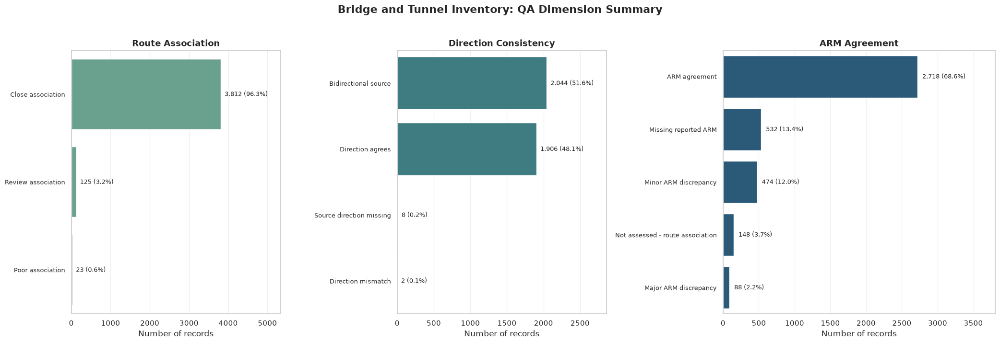

In [4]:
# SQL queries
queries = [
    (
        "Route Association",
        "route_association_status",
        """
        SELECT
            route_association_status,
            COUNT(*) AS record_count,
            ROUND(
                100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
                1
            ) AS percent_of_records
        FROM qa.vw_bt_qa_dimensions
        WHERE route_association_status != 'No route match'
        GROUP BY route_association_status
        ORDER BY record_count DESC;
        """
    ),
    (
        "Direction Consistency",
        "direction_status",
        """
        SELECT
            direction_status,
            COUNT(*) AS record_count,
            ROUND(
                100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
                1
            ) AS percent_of_records
        FROM qa.vw_bt_qa_dimensions
        WHERE route_association_status != 'No route match'
        GROUP BY direction_status
        ORDER BY record_count DESC;
        """
    ),
    (
        "ARM Agreement",
        "arm_agreement_status",
        """
        SELECT
            arm_agreement_status,
            COUNT(*) AS record_count,
            ROUND(
                100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
                1
            ) AS percent_of_records
        FROM qa.vw_bt_qa_dimensions
        WHERE route_association_status != 'No route match'
        GROUP BY arm_agreement_status
        ORDER BY record_count DESC;
        """
    )
]

# Plot setup
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 7),
    gridspec_kw={"width_ratios": [1, 1, 1.3]}
)

palette = sns.color_palette("crest", 3)

# Generate each plot
for ax, (title, status_col, sql), color in zip(axes, queries, palette):

    df = query_df(sql)

    sns.barplot(
        data=df,
        x="record_count",
        y=status_col,
        order=df[status_col].tolist(),
        color=color,
        ax=ax
    )

    # Add count and percentage labels
    max_count = df["record_count"].max()

    for patch, (_, row) in zip(ax.patches, df.iterrows()):
        ax.text(
            patch.get_width() + max_count * 0.025,
            patch.get_y() + patch.get_height() / 2,
            f"{int(row['record_count']):,} ({row['percent_of_records']:.1f}%)",
            va="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Number of records")
    ax.set_ylabel("")
    ax.set_xlim(0, max_count * 1.4)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", alpha=0.3)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Bridge and Tunnel Inventory: QA Dimension Summary",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [5]:
sql_within_route = """
WITH eligible AS (
    SELECT
        route_identifier,
        matched_direction,
        arm_difference_miles AS difference
    FROM qa.vw_bt_qa_dimensions
    WHERE arm_agreement_status IN (
        'ARM agreement',
        'Minor ARM discrepancy',
        'Major ARM discrepancy'
    )
    AND route_identifier IS NOT NULL
    AND arm_difference_miles IS NOT NULL
),

route_medians AS (
    SELECT
        route_identifier,
        matched_direction,
        COUNT(*) AS structure_count,
        percentile_cont(0.5)
            WITHIN GROUP (ORDER BY difference) AS median_difference
    FROM eligible
    GROUP BY route_identifier, matched_direction
    HAVING COUNT(*) >= 5
),

residuals AS (
    SELECT
        e.route_identifier,
        e.matched_direction,
        e.difference - r.median_difference AS centered_difference
    FROM eligible e
    JOIN route_medians r
        ON e.route_identifier = r.route_identifier
        AND e.matched_direction IS NOT DISTINCT FROM r.matched_direction
)

SELECT
    COUNT(*) AS structure_count,
    COUNT(DISTINCT (route_identifier, matched_direction))
        AS route_direction_groups,

    ROUND(
        (STDDEV_SAMP(centered_difference) * 5280)::numeric, 1
    ) AS within_route_stddev_ft,

    ROUND(
        (AVG(ABS(centered_difference)) * 5280)::numeric, 1
    ) AS mean_absolute_residual_ft,

    ROUND(
        (percentile_cont(0.5)
            WITHIN GROUP (ORDER BY ABS(centered_difference)) * 5280)::numeric, 1
    ) AS median_absolute_residual_ft,

    ROUND(
        (percentile_cont(0.90)
            WITHIN GROUP (ORDER BY ABS(centered_difference)) * 5280)::numeric, 1
    ) AS p90_absolute_residual_ft

FROM residuals;
"""

sql = """
WITH eligible AS (
    SELECT
        route_identifier,
        matched_direction,
        arm_difference_miles AS difference
    FROM qa.vw_bt_qa_dimensions
    WHERE arm_agreement_status IN (
        'ARM agreement',
        'Minor ARM discrepancy',
        'Major ARM discrepancy'
    )
    AND route_identifier IS NOT NULL
    AND arm_difference_miles IS NOT NULL
)
SELECT
    COUNT(*) AS structure_count,

    -- Signed difference: derived ARM minus reported ARM
    ROUND(
        (AVG(difference) * 5280)::numeric, 1
    ) AS mean_signed_difference_ft,

    ROUND(
        (percentile_cont(0.5)
            WITHIN GROUP (ORDER BY difference) * 5280)::numeric, 1
    ) AS median_signed_difference_ft,

    ROUND(
        (STDDEV_SAMP(difference) * 5280)::numeric, 1
    ) AS standard_deviation_ft,

    -- Absolute differences
    ROUND(
        (AVG(ABS(difference)) * 5280)::numeric, 1
    ) AS mean_absolute_difference_ft,

    ROUND(
        (percentile_cont(0.5)
            WITHIN GROUP (ORDER BY ABS(difference)) * 5280)::numeric, 1
    ) AS median_absolute_difference_ft,

    -- Root mean square error
    ROUND(
        (SQRT(AVG(difference * difference)) * 5280)::numeric, 1
    ) AS rmse_ft,

    -- Upper-tail discrepancy
    ROUND(
        (percentile_cont(0.90)
            WITHIN GROUP (ORDER BY ABS(difference)) * 5280)::numeric, 1
    ) AS p90_absolute_difference_ft,

    ROUND(
        (percentile_cont(0.95)
            WITHIN GROUP (ORDER BY ABS(difference)) * 5280)::numeric, 1
    ) AS p95_absolute_difference_ft,

    -- Percentage within exploratory thresholds
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE ABS(difference) <= 0.01
        ) / COUNT(*), 1
    ) AS pct_within_001_mi,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE ABS(difference) <= 0.05
        ) / COUNT(*), 1
    ) AS pct_within_005_mi,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE ABS(difference) <= 0.10
        ) / COUNT(*), 1
    ) AS pct_within_010_mi

FROM eligible;
"""

arm_summary = query_df(sql)
within_route_summary = query_df(sql_within_route)

# Combine both summaries horizontally
summary_comparison = pd.concat(
    [
        arm_summary.add_prefix("overall_"),
        within_route_summary.add_prefix("within_route_")
    ],
    axis=1
)

# Show all columns
pd.set_option("display.max_columns", None)

display(summary_comparison.T)

,0
overall_structure_count,3280.0
overall_mean_signed_difference_ft,-2916.2
overall_median_signed_difference_ft,1.7
overall_standard_deviation_ft,169405.7
overall_mean_absolute_difference_ft,3964.2
overall_median_absolute_difference_ft,10.2
overall_rmse_ft,169405.0
overall_p90_absolute_difference_ft,127.2
overall_p95_absolute_difference_ft,309.4
overall_pct_within_001_mi,82.9


### Why discrepancies?
One of the most likely causes of the derived ARM not lining up with WSDOT data is location of derived ARM in relation to the length of the bridge or tunnel.

![screenshot1](../images/map2.png) ![screenshot1](../images/map1.png) ![screenshot1](../images/map3.png)

---

As is visible below under 50ft ARM agreement should be considered fairly accurate for a course run of ST_InterpolatePoint in PostGIS between the State Route LRS layer and the bridges and tunnels geometry. 
<br>
Beyond 50ft structure length was examined as a possible contributor to ARM discrepancies. The grouped results do not demonstrate a consistent relationship between structure length and discrepancy magnitude. Although individual records may exhibit differences related to the location of their inventory reference point relative to the structure, structure length only shows a very local contribution to ARM discrepancies.

---

,discrepancy_category,structure_count,average_structure_length_ft,median_structure_length_ft
0,0–10 ft,1633,312.6,171.0
1,10–50 ft,1060,292.3,142.5
2,50–100 ft,194,346.8,116.0
3,100–500 ft,301,289.8,188.0
4,"500–2,640 ft",50,601.5,296.0
5,"≥2,640 ft",41,240.2,135.0


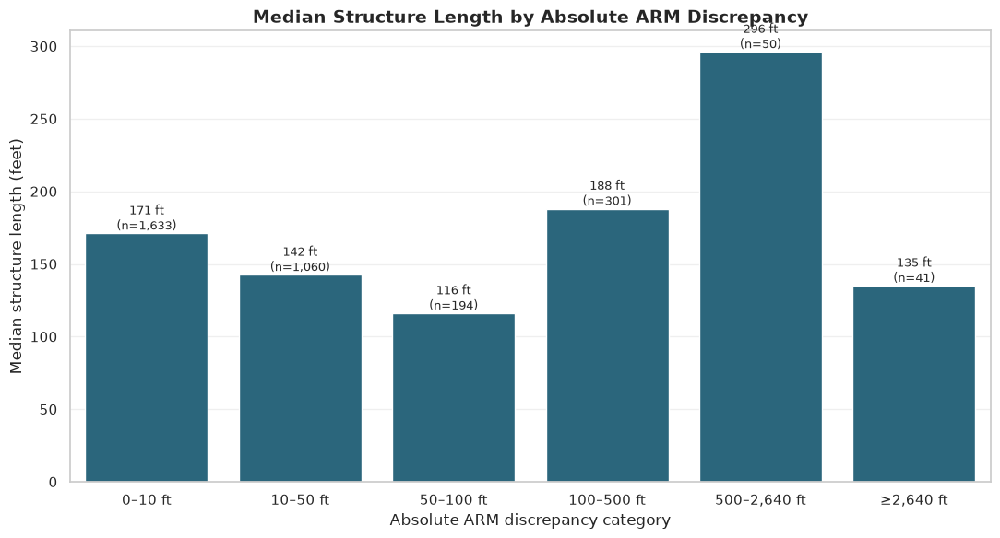

In [16]:
sql = """
WITH eligible AS (
    SELECT
        q.objectid,
        ABS(q.arm_difference_feet) AS absolute_arm_difference_ft,
        b.structurelengthbyfeet AS structure_length_ft
    FROM qa.vw_bt_qa_dimensions q
    JOIN ref.all_bridge_tunnel b
        ON q.objectid = b.objectid
    WHERE q.arm_agreement_status IN (
        'ARM agreement',
        'Minor ARM discrepancy',
        'Major ARM discrepancy'
    )
    AND q.route_identifier IS NOT NULL
    AND q.arm_difference_feet IS NOT NULL
    AND b.structurelengthbyfeet IS NOT NULL
),

categorized AS (
    SELECT
        *,
        CASE
            WHEN absolute_arm_difference_ft < 10
                THEN '0–10 ft'
            WHEN absolute_arm_difference_ft < 50
                THEN '10–50 ft'
            WHEN absolute_arm_difference_ft < 100
                THEN '50–100 ft'
            WHEN absolute_arm_difference_ft < 500
                THEN '100–500 ft'
            WHEN absolute_arm_difference_ft < 2640
                THEN '500–2,640 ft'
            ELSE '≥2,640 ft'
        END AS discrepancy_category,

        CASE
            WHEN absolute_arm_difference_ft < 10 THEN 1
            WHEN absolute_arm_difference_ft < 50 THEN 2
            WHEN absolute_arm_difference_ft < 100 THEN 3
            WHEN absolute_arm_difference_ft < 500 THEN 4
            WHEN absolute_arm_difference_ft < 2640 THEN 5
            ELSE 6
        END AS category_order

    FROM eligible
)

SELECT
    discrepancy_category,
    COUNT(*) AS structure_count,

    ROUND(
        AVG(structure_length_ft)::numeric, 1
    ) AS average_structure_length_ft,

    ROUND(
        percentile_cont(0.5)
        WITHIN GROUP (
            ORDER BY structure_length_ft
        )::numeric, 1
    ) AS median_structure_length_ft

FROM categorized
GROUP BY discrepancy_category, category_order
ORDER BY category_order;
"""

length_by_discrepancy = query_df(sql)
display(length_by_discrepancy)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=length_by_discrepancy,
    x="discrepancy_category",
    y="median_structure_length_ft",
    color=sns.color_palette("crest", 5)[3],
    ax=ax
)

# Annotate average length and record count
for i, row in length_by_discrepancy.iterrows():
    ax.text(
        i,
        row["median_structure_length_ft"],
        f'{row["median_structure_length_ft"]:,.0f} ft\n(n={row["structure_count"]:,})',
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Median Structure Length by Absolute ARM Discrepancy",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Absolute ARM discrepancy category")
ax.set_ylabel("Median structure length (feet)")

ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

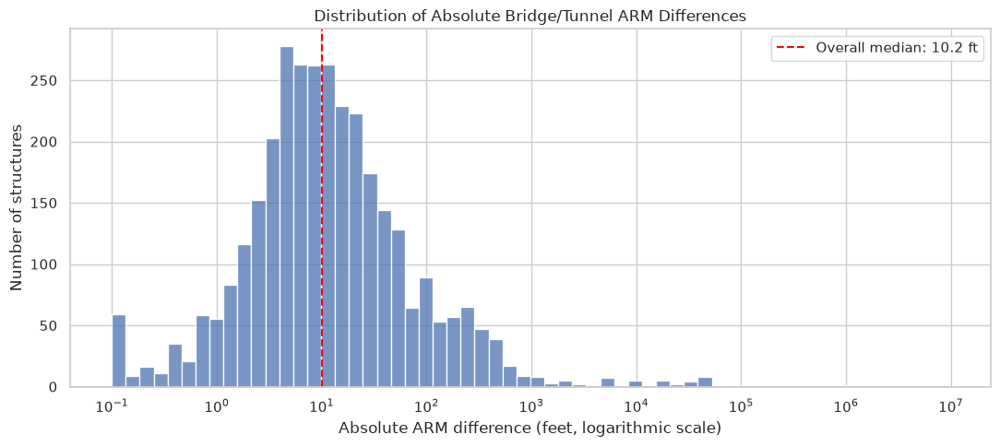

In [7]:
# Use signed ARM difference to derive absolute difference in feet
plot_data = query_df("""
SELECT
    ABS(arm_difference_miles * 5280.0) AS absolute_difference_ft
FROM qa.vw_bt_qa_dimensions
WHERE arm_agreement_status IN (
    'ARM agreement',
    'Minor ARM discrepancy',
    'Major ARM discrepancy'
)
AND route_identifier IS NOT NULL
AND arm_difference_miles IS NOT NULL;
""")

# Log scale cannot display zero, so apply a small plotting floor
plot_data["absolute_difference_ft"] = (
    plot_data["absolute_difference_ft"].clip(lower=0.1)
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=plot_data,
    x="absolute_difference_ft",
    bins=60,
    log_scale=True,
    ax=ax
)

ax.axvline(
    10.2,
    color="red",
    linestyle="--",
    label="Overall median: 10.2 ft"
)

ax.set_title("Distribution of Absolute Bridge/Tunnel ARM Differences")
ax.set_xlabel("Absolute ARM difference (feet, logarithmic scale)")
ax.set_ylabel("Number of structures")
ax.legend()

plt.tight_layout()
plt.show()

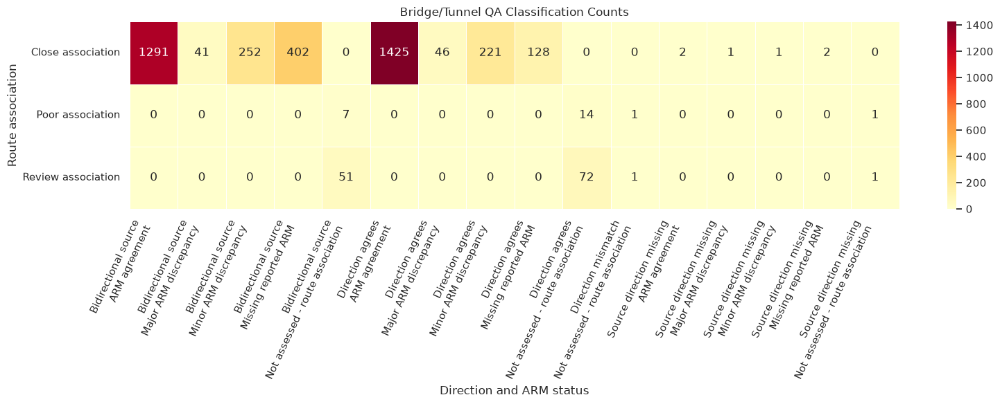

In [8]:

sql = """
SELECT
    route_association_status,
    direction_status,
    arm_agreement_status,
    COUNT(*) AS record_count
FROM qa.vw_bt_qa_dimensions
WHERE route_association_status NOT LIKE 'No route match'
GROUP BY
    route_association_status,
    direction_status,
    arm_agreement_status
ORDER BY
    route_association_status,
    direction_status,
    arm_agreement_status;
"""

qa_summary = query_df(sql)

# Consistent ordering for readability
route_order = [
    "Close association",
    "Review association",
    "Poor association",
]

direction_order = [
    "Direction agrees",
    "Bidirectional source",
    "Direction mismatch",
    "Source direction missing",
    "Matched direction missing"
]

arm_order = [
    "ARM agreement",
    "Minor ARM discrepancy",
    "Major ARM discrepancy",
    "Not assessed - direction",
    "Not assessed - route association",
    "Missing reported ARM",
    "Missing derived ARM"
]

qa_summary["direction_arm"] = (
    qa_summary["direction_status"]
    + "\n"
    + qa_summary["arm_agreement_status"]
)

heatmap_data = qa_summary.pivot(
    index="route_association_status",
    columns="direction_arm",
    values="record_count"
).fillna(0)

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white"
)

plt.title("Bridge/Tunnel QA Classification Counts")
plt.xlabel("Direction and ARM status")
plt.ylabel("Route association")
plt.xticks(rotation=65, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### SR 2

Focusing on the ARM discrepancies along highway 2, there is a distance between 6-8miles, with 4 structures at exactly 8 mile distance from the recorded arm. This strongly suggests an offset in the actual method of measurement. This is displayed below.

In [9]:
sr002d = bridge_tunnel[
    bridge_tunnel["route_identifier"].eq("002d")
].copy()

sr002d_extreme = sr002d[
    sr002d["absolute_arm_difference"] > 1
].copy()

sr002d_route = query_gdf("""
    SELECT
        route_identifier,
        inventory_direction,
        geom
    FROM ref.state_route_lrs
    WHERE route_identifier = '002d'
""")

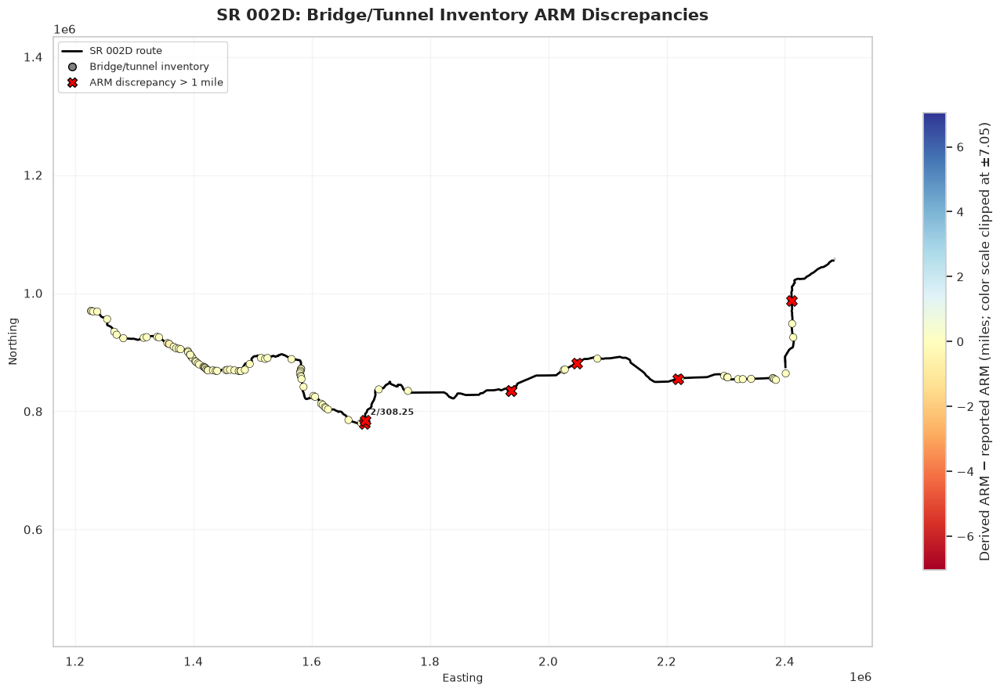

In [10]:
# Copy GeoDataFrames
points = sr002d.copy()
route = sr002d_route.copy()
extreme = sr002d_extreme.copy()

# Ensure matching coordinate systems
if route.crs != points.crs:
    route = route.to_crs(points.crs)

if extreme.crs != points.crs:
    extreme = extreme.to_crs(points.crs)

# Remove records without geometry or ARM difference
points = points[
    points.geometry.notna()
    & points["arm_difference_miles"].notna()
].copy()

extreme = extreme[extreme.geometry.notna()].copy()

if points.empty:
    raise ValueError("No valid SR 002D structure records to plot.")

# --------------------------------------------------
# Color scaling
# --------------------------------------------------

# Use the 95th percentile to prevent extreme values
# from compressing the colors of the remaining records.
abs_differences = points["arm_difference_miles"].abs()

color_limit = np.nanpercentile(abs_differences, 95)

if not np.isfinite(color_limit) or color_limit == 0:
    color_limit = 0.01

# Clip values for visualization only; original data is unchanged.
points["_plot_difference"] = points["arm_difference_miles"].clip(
    lower=-color_limit,
    upper=color_limit
)

# --------------------------------------------------
# Create map
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

# 1. State Route geometry
route.plot(
    ax=ax,
    color="black",
    linewidth=2,
    zorder=1
)

# 2. All bridge/tunnel records, colored by signed ARM difference
points.plot(
    ax=ax,
    column="_plot_difference",
    cmap="RdYlBu",
    vmin=-color_limit,
    vmax=color_limit,
    markersize=45,
    edgecolor="black",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "label": (
            f"Derived ARM − reported ARM (miles; "
            f"color scale clipped at ±{color_limit:.2f})"
        ),
        "shrink": 0.75
    },
    zorder=2
)

# 3. Extreme discrepancies highlighted in red
if not extreme.empty:
    extreme.plot(
        ax=ax,
        color="red",
        marker="X",
        markersize=100,
        edgecolor="black",
        linewidth=0.7,
        zorder=3
    )

    # Label extreme structures
    geometry_col = extreme.geometry.name
    
    for _, row in extreme.iterrows():
        point = row[geometry_col].representative_point()
    
    label = str(row["structurenumber"])

    ax.annotate(
        label,
        xy=(point.x, point.y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        zorder=4
    )
# --------------------------------------------------
# Legend and formatting
# --------------------------------------------------

legend_items = [
    Line2D(
        [0], [0],
        color="black",
        linewidth=2,
        label="SR 002D route"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="white",
        markerfacecolor="gray",
        markeredgecolor="black",
        markersize=7,
        linestyle="None",
        label="Bridge/tunnel inventory"
    ),
    Line2D(
        [0], [0],
        marker="X",
        color="red",
        markeredgecolor="black",
        markersize=9,
        linestyle="None",
        label="ARM discrepancy > 1 mile"
    )
]

ax.legend(
    handles=legend_items,
    loc="upper left",
    frameon=True,
    fontsize=9
)

ax.set_title(
    "SR 002D: Bridge/Tunnel Inventory ARM Discrepancies",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Easting")
ax.set_ylabel("Northing")

ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [11]:
m_002d = sr002d.explore(
    column="arm_difference_miles",
    cmap="RdYlBu",
    tooltip=[
        "structurenumber",
        "lrsrouteid",
        "lrsinventorydirection",
        "reported_arm",
        "derived_arm",
        "arm_difference_miles",
        "distance_to_route"
    ],
    marker_kwds={"radius": 5},
    name="Bridge/tunnel inventory"
)

sr002d_route.explore(
    m=m_002d,
    color="black",
    name="SR 002D route",
    style_kwds={"weight": 3}
)

sr002d_extreme.explore(
    m=m_002d,
    color="red",
    tooltip=[
        "structurenumber",
        "reported_arm",
        "derived_arm",
        "arm_difference_miles",
        "distance_to_route"
    ],
    marker_kwds={"radius": 7},
    name="ARM discrepancy > 1 mile"
)

folium.LayerControl(collapsed=False).add_to(m_002d)

m_002d

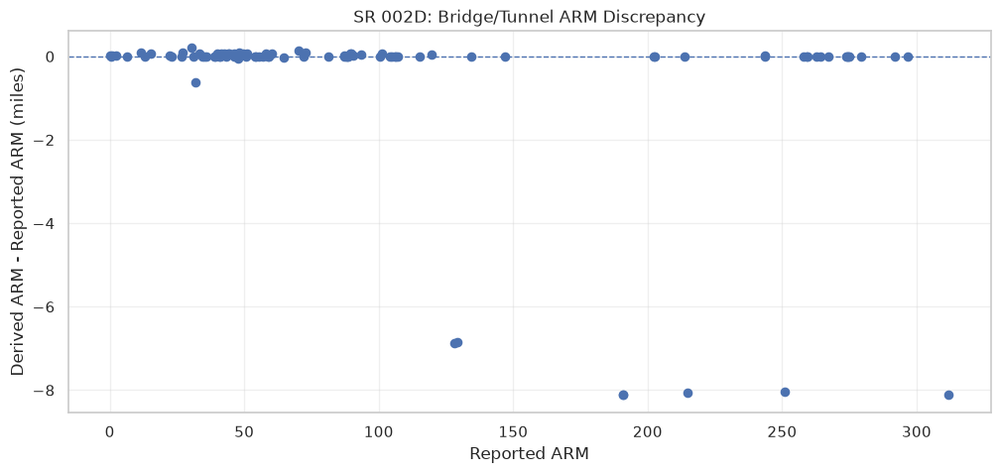

In [12]:
sr002d = sr002d.sort_values("reported_arm").copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    sr002d["reported_arm"],
    sr002d["arm_difference_miles"],
    s=35
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("SR 002D: Bridge/Tunnel ARM Discrepancy")
ax.set_xlabel("Reported ARM")
ax.set_ylabel("Derived ARM - Reported ARM (miles)")
ax.grid(True, alpha=0.3)

plt.show()

___

The SR 002D investigation identified seven bridge and tunnel records with absolute differences greater than one mile between reported inventory ARM and measures derived from the State Route LRS geometry. Several records are located very close to the matched route geometry, including structures within a few feet, suggesting that spatial association alone does not explain the observed discrepancies. The differences also exhibit a relatively consistent pattern across sections of the route, with offsets of approximately 6.9 miles around ARM 128–129 and approximately 8.0–8.1 miles across ARM 190–312. This suggests a possible difference in measure referencing, route calibration, or historical route alignment rather than isolated structure-length discrepancies.

This would be a area to directly investigate.

___

___

# Dig Once - Broadband Utilities

‘Dig once’ is a collaborative approach for broadband utility providers to install conduit and fiber concurrently with highway construction projects.
## Process for participating in a ‘Dig Once’ project
### Find a ‘dig once’ opportunity
1. Sign up for email alerts through the GovDelivery subscription service for Dig Once - Broadband Utilities
2. Search for ‘dig once’ opportunities by using our Dig Once – Broadband Utilities Map
3. Inquire directly about a specific WSDOT project by contacting us at broadband.utilities@wsdot.wa.gov

### Coordinating with WSDOT

1. The Broadband Utility Coordinator will assist with connecting you to the project design team to confirm the project is suitable for ‘dig once’ and further coordination.
2. The WSDOT project team will confirm if ‘dig once’ is feasible.
3. A signed Utility Accommodation Application (Form 224-696) is required to continue coordination with WSDOT (see Utility Accommodation Permits and Franchises for more information).

### Broadband design and construction

1. Design your broadband infrastructure to be installed concurrently with the WSDOT project in coordination with the WSDOT project team.
2. Broadband utility providers will be responsible for all costs related, but not limited to, permitting, labor, equipment, materials, and maintenance of the installation.

## Why ‘Dig Once’?

WSDOT has developed ‘dig once’ policies in response to federal and state legislation that emphasizes the importance for broadband access. The benefits of practicing this approach may include:

1. Maximizing efficiencies of the highway right of way
2. Reducing costs to install conduit and fiber
3. Minimizing disruptions to the travelling public
4. Reducing the number of excavations within the highway right of way   

For more information see  23 CFR 645.307 and RCW 47.44.160 

## Which WSDOT projects have ‘Dig Once’ opportunities?

Not all WSDOT projects are conducive to this type of collaboration. Coordination will be needed directly with the WSDOT regional project and utility staff to determine feasibility.

The projects portrayed on the Dig Once – Broadband Utilities Map are part of the WSDOT Project Delivery Plan and include projects that are most likely to be available for ‘dig once’ collaboration, including:

1. Improvement (e.g. highway widening)
2. Preservation (e.g. repaving a section of highway)
3. Traffic Operations (e.g. changeable message sign or traffic cameras)

[Source](https://wsdot.wa.gov/engineering-standards/design-topics/utilities-railroad-agreements/dig-once-broadband-utilities)

---

[WSDOT Dig Once Map](https://wsdot.maps.arcgis.com/apps/webappviewer/index.html?id=0635854cd487427f9464d802dcd92d11)

---

### WSDOT Current Project Delivery Plan

[Feature Service](https://data.wsdot.wa.gov/arcgis/rest/services/Shared/WSDOTProjectDeliveryPlanCurrent/FeatureServer)


### LRS dig once opportunites

Looking at the WSDOT Dig Once Opportunities map online, it is created through querying the Current Project Delivery Plan feature service REST API with the following parameters:
* (AdDate > timestamp '2025-01-01 07:59:59') AND 
  (ProgramCode = 'I' OR ProgramCode = 'P' OR ProgramCode = 'Q')
<br>
This was easily recreated in postgres after loading the current project delivery table using SQL and then in PostGIS, with the State Route LRS layer already loaded, running the same processes as the bridges and tunnels on dig once locations was straighforward. The areas of discrepancy were focused around 405 on the Eastside of Seattle, where the state route layer had a few gaps. Below are the results.

___

___

![Dig Once LRS](../images/dig_once.png)

In [13]:
dig_once = query_gdf("""
SELECT *
FROM analysis.dig_once
""", geom_col='geom')
dig_once

,objectid,projectnumber,projecttitle,workdescription,bookdescription,lastupdated,cpmsregioncode,regiondesc,countyname,legdistrict,programcode,programdesc,programdomain,subprogramcode,subprogramdesc,subprogramdomain,subcategorycode,subcategorydesc,subcategorydomain,improvementtypecode,improvementtypedesc,imptypedomain,projdef,beginpe,envirdoc,rwcert,addate,opercomplete,totaldollars,routeidentifier,stateroutenumber,relatedroutetype,relatedroutequalifier,beginstateroutemilepost,endstateroutemilepost,middlestateroutemilepost,beginaccumulatedroutemile,endaccumulatedroutemile,middleaccumulatedroutemile,inventorydirection,armcalcresponsedate,longitude,latitude,shape__length,source,geom
0,60,311272E,SR 112/E Rasmussen Creek - Emergency Project,"Embankment slope stabilization, Slope ID #3746","The slope embankment (slope ID #3746), at MP 5...",1675584000000,OR,Olympic,Clallam,24,P,Preservation,P - Preservation,P3,Other Facilities,P3 - Other Facilities,PE,Unstable Slopes,PE - Unstable Slopes,HE,Unstable Slope - Emergency Event,HE - Unstable Slope - Emergency Event,NaN,1.681456e+12,1.735546e+12,NaN,1.750057e+12,1.761894e+12,628199.0,112,112,,,5.35,5.43,5.39,5.35,5.43,5.39,B,1704009600000,-124.465730,48.322586,421.856077,FeatureServer,"LINESTRING (675442.338 1114700.368, 675453.65 ..."
1,67,311260E,SR 112/Pysht River - Emergency Repairs,Repair river embankments,Roadway embankments have been compromised and ...,1648796400000,OR,Olympic,Clallam,24,P,Preservation,P - Preservation,P3,Other Facilities,P3 - Other Facilities,PE,Unstable Slopes,PE - Unstable Slopes,HE,Unstable Slope - Emergency Event,HE - Unstable Slope - Emergency Event,NaN,1.650524e+12,NaN,NaN,1.774249e+12,1.796026e+12,3849957.0,112,112,,,25.60,26.50,26.05,25.53,26.43,25.98,B,1704009600000,-124.165926,48.191011,4749.544199,FeatureServer,"LINESTRING (744754.326 1061995.883, 744785.917..."
2,76,311261E,SR 112/W Rasmussen Creek - Emergency Repair,Repair river embankments for slope #3718,Unstable slope 3718 has been compromised and i...,1671782400000,OR,Olympic,Clallam,24,P,Preservation,P - Preservation,P3,Other Facilities,P3 - Other Facilities,PE,Unstable Slopes,PE - Unstable Slopes,HE,Unstable Slope - Emergency Event,HE - Unstable Slope - Emergency Event,NaN,1.657264e+12,NaN,NaN,1.660720e+12,1.663744e+12,1080603.0,112,112,,,4.60,4.70,4.65,4.60,4.70,4.65,B,1704009600000,-124.477754,48.328475,527.116573,FeatureServer,"LINESTRING (672522.277 1116927.109, 672529.63 ..."
3,234,100598E,I-5/Cain Creek to Semiahmoo Bay- Fish Passage,Remove Fish Barrier (ID # 995726),Remove the existing fish passage barrier and r...,1620975600000,NWR,Northwest,Whatcom,42,I,Improvement,I - Improvement,I4,Environmental Retrofit,I4 - Environmental Retrofit,IL,Fish Barriers,IL - Fish Barriers,P1,Fish Barrier Retrofit,P1 - Fish Barrier Retrofit,1.759302e+12,1.762243e+12,1.764662e+12,1.851059e+12,1.853478e+12,1.919660e+12,2113982.0,005,005,,,275.25,275.40,275.33,275.23,275.38,275.31,B,1704009600000,-122.738565,48.988867,1581.489335,FeatureServer,"MULTILINESTRING ((1102819.743 1340828.534, 110..."
4,326,311271E,SR 112/W Rasmussen Creek - Emergency Project,"Embankment slope stabilization, Slope ID #3747","The slope embankment (slope ID #3747), at MP 4...",1675843200000,OR,Olympic,Clallam,24,P,Preservation,P - Preservation,P3,Other Facilities,P3 - Other Facilities,PE,Unstable Slopes,PE - Unstable Slopes,HE,Unstable Slope - Emergency Event,HE - Unstable Slope - Emergency Event,NaN,1.681456e+12,1.735546e+12,NaN,1.750057e+12,1.761894e+12,814939.0,112,112,,,4.71,4.73,4.72,4.71,4.73,4.72,B,1704009600000,-124.476249,48.328383,105.570381,FeatureServer,"LINESTRING (673083.649 1116805.122, 673086.003..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1336,1357,639521M,US 395/Immel Rd to Arden - Paving,HMA paving with basic safety restoration,Asphalt concrete pavement requires rehabili

Once the dig once opportunities are loaded into the map, it is easy to explore them by sub category. This project lends itself to exploring all this available data according to the LRS relationship between derived ARM and Recorded WSDOT ARM data vs mile as LRS events according to project type, cost, or any other category available in the data. 
<br><br>
A quick exploration of subtypes of projects below:

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

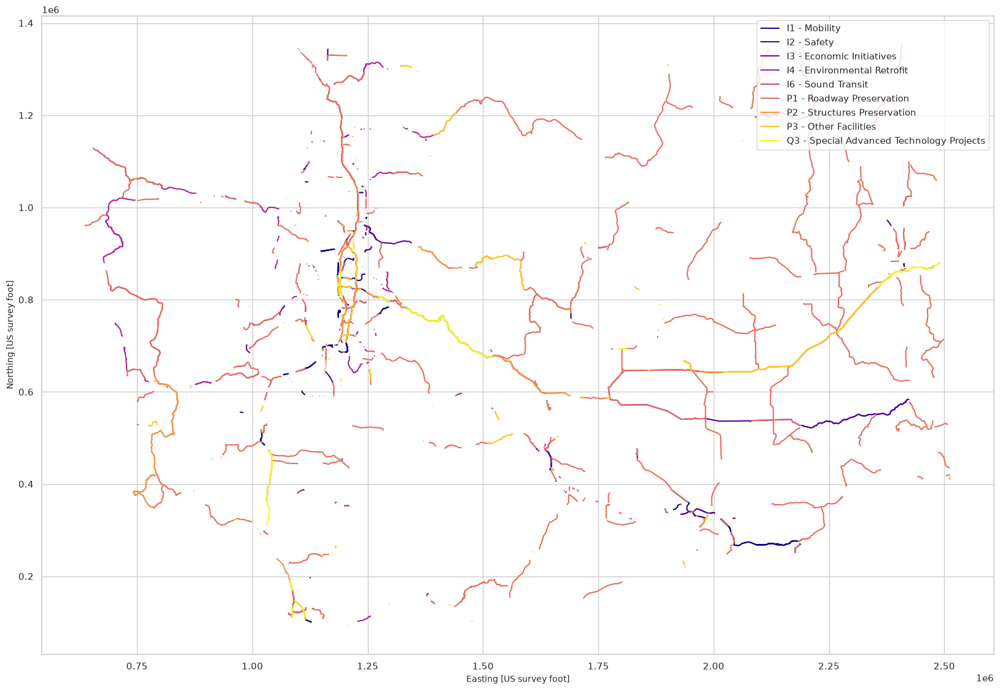

In [14]:
dig_once.plot(column='subprogramdomain', cmap='plasma', legend=True, figsize=(20, 40))

In [15]:
dig_once.explore(column='subprogramdomain', cmap='plasma', legend=True, figsize=(20, 40))